In [ ]:

# Verificar valores ausentes e registros duplicados

print("Dimensões originais:", df.shape)

print("\nValores ausentes por coluna:")
print(df.isna().sum())

print("\nTotal de valores ausentes:")
print(df.isna().sum().sum())

print("\nQuantidade de linhas duplicadas:")
print(df.duplicated().sum())

print("\nQuantidade de identificadores UDI repetidos:")
print(df["UDI"].duplicated().sum())


NameError: name 'df' is not defined

In [ ]:

import pandas as pd
import numpy as np
from google.colab import files

# Selecionar o arquivo CSV do projeto
uploaded = files.upload()

# Ler o arquivo enviado
nome_arquivo = next(iter(uploaded))
df = pd.read_csv(nome_arquivo)

# Conferir se os dados foram carregados
print("Arquivo:", nome_arquivo)
print("Dimensões:", df.shape)
display(df.head())


KeyboardInterrupt: 

Saving ai4i2020.csv to ai4i2020.csv


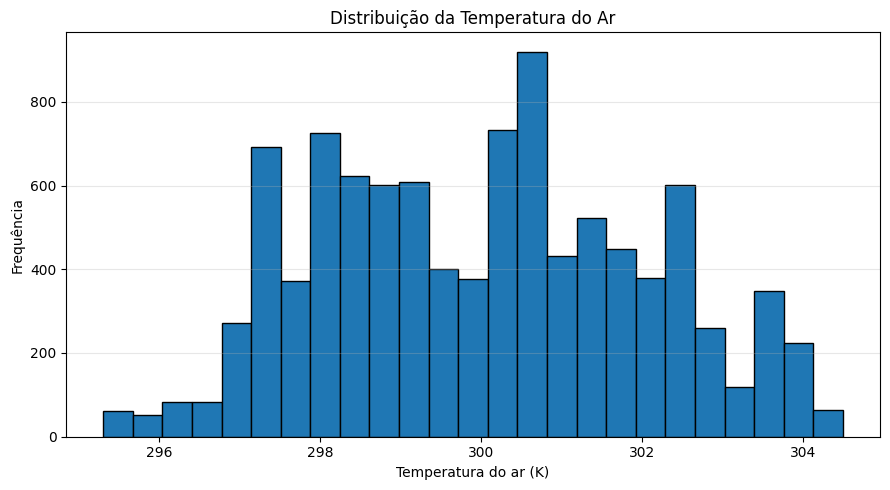

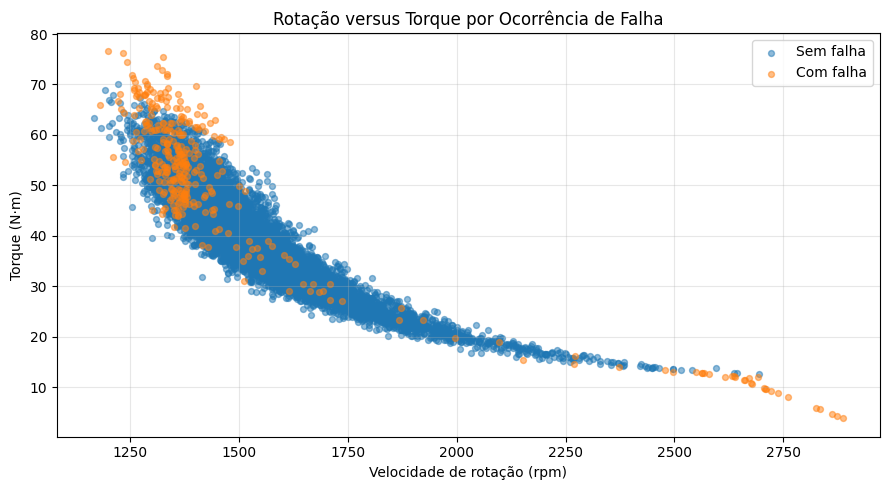

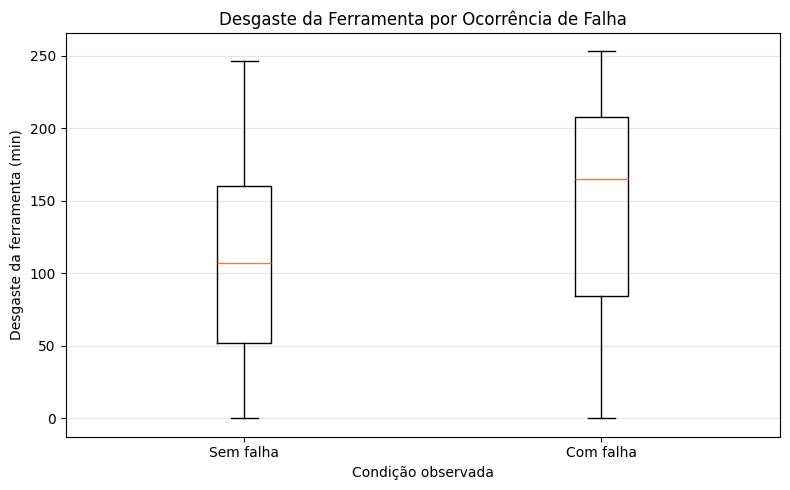

Gráficos gerados e salvos em PNG.
Quantidade de registros analisados: 10000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

# 1. Carregar o dataset, caso ainda não esteja carregado
if "df" not in globals():
    from google.colab import files
    uploaded = files.upload()
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(nome_arquivo)

# Criar pasta para salvar os gráficos
os.makedirs("graficos_evtec", exist_ok=True)

# Verificar se as colunas necessárias existem
colunas = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

faltantes = [c for c in colunas if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas não encontradas: {faltantes}")

# GRÁFICO 1 — Distribuição da temperatura do ar
plt.figure(figsize=(9, 5))
plt.hist(df["Air temperature [K]"].dropna(),
         bins=25, edgecolor="black")
plt.title("Distribuição da Temperatura do Ar")
plt.xlabel("Temperatura do ar (K)")
plt.ylabel("Frequência")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("graficos_evtec/01_temperatura_ar.png", dpi=200)
plt.show()

# GRÁFICO 2 — Relação entre rotação e torque, por ocorrência de falha
plt.figure(figsize=(9, 5))

for falha, rotulo in [(0, "Sem falha"), (1, "Com falha")]:
    grupo = df[df["Machine failure"] == falha]
    plt.scatter(
        grupo["Rotational speed [rpm]"],
        grupo["Torque [Nm]"],
        alpha=0.5,
        s=18,
        label=rotulo
    )

plt.title("Rotação versus Torque por Ocorrência de Falha")
plt.xlabel("Velocidade de rotação (rpm)")
plt.ylabel("Torque (N·m)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("graficos_evtec/02_rotacao_torque_falha.png", dpi=200)
plt.show()

# GRÁFICO 3 — Desgaste da ferramenta por ocorrência de falha
grupos = [
    df.loc[df["Machine failure"] == 0, "Tool wear [min]"].dropna(),
    df.loc[df["Machine failure"] == 1, "Tool wear [min]"].dropna()
]

plt.figure(figsize=(8, 5))
plt.boxplot(grupos, tick_labels=["Sem falha", "Com falha"])
plt.title("Desgaste da Ferramenta por Ocorrência de Falha")
plt.xlabel("Condição observada")
plt.ylabel("Desgaste da ferramenta (min)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("graficos_evtec/03_desgaste_por_falha.png", dpi=200)
plt.show()

# Criar um arquivo ZIP com as três imagens
with zipfile.ZipFile("graficos_evtec.zip", "w") as arquivo_zip:
    for nome in os.listdir("graficos_evtec"):
        arquivo_zip.write(
            os.path.join("graficos_evtec", nome),
            arcname=nome
        )

print("Gráficos gerados e salvos em PNG.")
print("Quantidade de registros analisados:", len(df))

# Baixar as imagens para o computador
from google.colab import files
files.download("graficos_evtec.zip")


In [ ]:
colunas = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

print(df[colunas].describe().T)

                           count        mean         std     min     25%  \
Air temperature [K]      10000.0   300.00493    2.000259   295.3   298.3   
Process temperature [K]  10000.0   310.00556    1.483734   305.7   308.8   
Rotational speed [rpm]   10000.0  1538.77610  179.284096  1168.0  1423.0   
Torque [Nm]              10000.0    39.98691    9.968934     3.8    33.2   
Tool wear [min]          10000.0   107.95100   63.654147     0.0    53.0   

                            50%     75%     max  
Air temperature [K]       300.1   301.5   304.5  
Process temperature [K]   310.1   311.1   313.8  
Rotational speed [rpm]   1503.0  1612.0  2886.0  
Torque [Nm]                40.1    46.8    76.6  
Tool wear [min]           108.0   162.0   253.0  


In [ ]:
print("Dimensões:", df.shape)
print("\nValores ausentes por coluna:")
print(df.isna().sum())

print("\nLinhas duplicadas:")
print(df.duplicated().sum())

print("\nUDI duplicados:")
print(df["UDI"].duplicated().sum())

Dimensões: (10000, 14)

Valores ausentes por coluna:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Linhas duplicadas:
0

UDI duplicados:
0


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
print(df["Machine failure"].value_counts(dropna=False))

colunas_falha = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[colunas_falha].sum())

Machine failure
0    9661
1     339
Name: count, dtype: int64
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64
